# Single qubit quantum gates

Single qubit gates means, we have single state vector like psi

$$
|\psi\rangle = \alpha|0\rangle + \beta|1\rangle
$$

Where,

$\alpha^2 + \beta^2 = 1$

- That type of gate transform one qubit state.

In [5]:
import numpy as np

In [6]:
zero = np.array([[1], [0]], dtype=complex)
one = np.array([[0], [1]], dtype=complex)

# Also we can represent these by up and down

up = zero
down = one

print(zero)
print(one)
print(zero.shape)

[[1.+0.j]
 [0.+0.j]]
[[0.+0.j]
 [1.+0.j]]
(2, 1)


In [7]:
# But it is easier to write like this

zero = np.array([1, 0], dtype=complex)
one = np.array([0, 1], dtype=complex)

print(zero)
print(one)

print(zero.shape)

[1.+0.j 0.+0.j]
[0.+0.j 1.+0.j]
(2,)


In [11]:
# Gates

I = np.eye(2)

X = np.array([(0, 1), (1, 0)], dtype=complex)
Y = np.array([(0, -1j), (1j, 0)], dtype=complex)
Z = np.array([(1, 0), (0, -1)], dtype=complex)
H = np.array([(1, 1), (1, -1)], dtype=complex) / np.sqrt(2)

# Here X = PauliX, Y = PauliY, Z = PauliZ
# H -> Hadamard gate or the Hadamard transformation used to generate superposition state

gates = {"I": I, "X": X, "Y": Y, "Z": Z, "H": H}

In [9]:
# See what each gate does to |0> and |1>

for name, gate in gates.items():
    print(f"\n{name} gate")
    print("--------")
    print("on |0>:\n", gate @ zero)
    print("on |1>:\n", gate @ one)


I gate
--------
on |0>:
 [1.+0.j 0.+0.j]
on |1>:
 [0.+0.j 1.+0.j]

X gate
--------
on |0>:
 [0.+0.j 1.+0.j]
on |1>:
 [1.+0.j 0.+0.j]

Y gate
--------
on |0>:
 [0.+0.j 0.+1.j]
on |1>:
 [0.-1.j 0.+0.j]

Z gate
--------
on |0>:
 [1.+0.j 0.+0.j]
on |1>:
 [ 0.+0.j -1.+0.j]

H gate
--------
on |0>:
 [0.70710678+0.j 0.70710678+0.j]
on |1>:
 [ 0.70710678+0.j -0.70710678+0.j]


In [10]:
ket_zero = zero
ket_one = one

bra_zero = zero.conj().T
bra_one = one.conj().T

derived_I = ket_zero @ bra_zero + ket_one @ bra_one

# I = |0><0| + |1><1|
if np.array_equal(derived_I, I): 
    print("Verified: I = |0><0| + |1><1|")
else:
    print("Unable to verify: I = |0><0| + |1><1|")

Unable to verify: I = |0><0| + |1><1|


### Similarly to I(Identity), lets get Pauli Gates

In [11]:
PauliX = X
PauliY = Y
PauliZ = Z

In [12]:
X = ket_one @ bra_zero + ket_zero @ bra_one

print(np.array_equal(X, PauliX))

False


In [13]:
Y = ket_one @ bra_zero - ket_zero @ bra_one
print(np.array_equal(Y, ((-1j)*PauliY)))

False


In [14]:
Z = ket_zero @ bra_zero - ket_one @ bra_one
print(np.array_equal(Z, PauliZ))

False


In [15]:
np.array_equal(PauliX@PauliZ, (-1j)*PauliY)

True

### Let's verify unitary

A valid quantum gate is represented by a unitary matrix. For each gate $(U)$, verify

$$
U^\dagger U=I,
$$

where $U^\dagger$ is the conjugate transpose. In NumPy, use `U.conj().T`.

In [16]:
for name, U in gates.items():
    print(name, np.allclose(U.conj().T @ U, np.eye(2)))

I True
X True
Y True
Z True
H True


### Look into calculation of measurement probability

In [21]:
def measurement_probabilities(state):
    """Return probabilities for measuring |0> and |1>"""
    return np.abs(state) ** 2

In [22]:
state = H @ zero
probabilities = measurement_probabilities(state)
print("State:", state)
print("P(|0>):", probabilities[0])
print("P(|1>):", probabilities[1])

State: [0.70710678+0.j 0.70710678+0.j]
P(|0>): 0.4999999999999999
P(|1>): 0.4999999999999999


### Making CNOT gate
- It is two qubits gate
- It flips second qubit(target) if first qubit(control) is $|1\rangle$

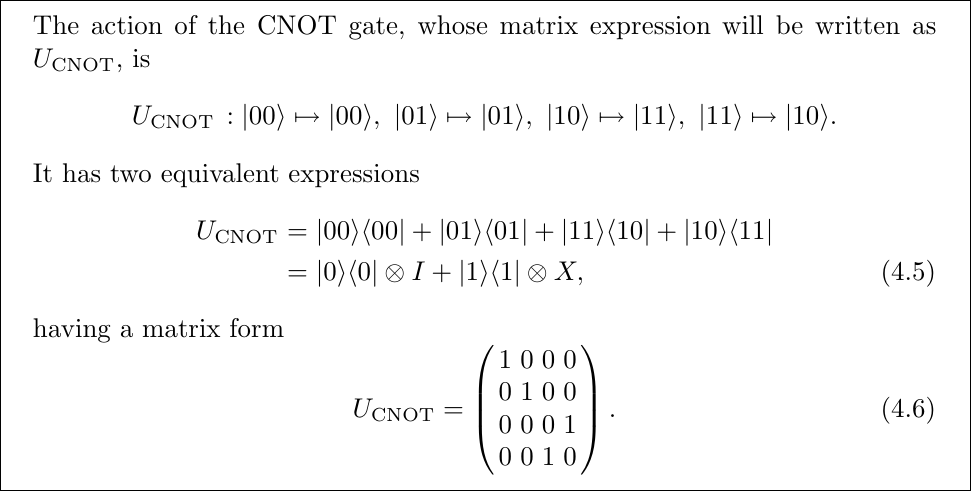

In [1]:
import numpy as np

# Define components I and X(Pauli X gate)
I = np.eye(2)
X = np.array([(0, 1), (1, 0)])

In [4]:
# Projections - P0 and P1
# P0 is the outer product of state vector |0> ie. |0><0|
# And P1 is the outer product of |1> ie. |1><1|

# Define the state vectors (kets)
ket_0 = np.array([1, 0])
ket_1 = np.array([0, 1])

# Finding bra vectors
bra_0 = ket_0.conj().T
bra_1 = ket_1.conj().T

# Projectors
P0 = ket_0 @ bra_0
P1 = ket_1 @ bra_1

# Or can use np.outer
P0 = np.outer(ket_0, bra_0)
P1 = np.outer(ket_1, bra_1)

In [6]:
# Final gate (CNOT) is formed by taking P0 tensor I + P1 tensor X
# We use np.korn

U_CNOT = np.kron(P0, I) + np.kron(P1, X)

print(U_CNOT)

[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]]


### CCNOT Gate

- CCNOT gate is also known as Toff0li gate

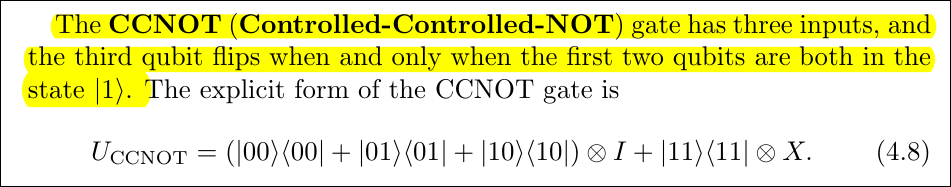

In [8]:
# Here first part is do nothing and second part is flip. There are two control bits

ket_00 = np.kron(ket_0, ket_0)
bra_00 = ket_00.conj().T

ket_11 = np.kron(ket_1, ket_1)
bra_11 = ket_11.conj().T

# Or we can get bra using tensor product of bras

# Also we need bra and ket of 01 and 10
ket_01 = np.kron(ket_0, ket_1)
bra_01 = np.kron(bra_0, bra_1)

ket_10 = np.kron(ket_1, ket_0)
bra_10 = np.kron(bra_1, bra_0)

In [9]:
# Find out the projections

P_00 = np.outer(ket_00, bra_00)
P_01 = np.outer(ket_01, bra_01)
P_10 = np.outer(ket_10, bra_10)
P_11 = np.outer(ket_11, bra_11)

In [10]:
# The CCNOT/Toffoli gate is now

U_CCNOT = np.kron((P_00 + P_01 + P_10), I) + np.kron(P_11, X)
print(U_CCNOT)

[[1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 1. 0.]]


### Forming Hadamard gate 
- Can be make using pauli X and pali Z that means it flips bit and phase simultaneously.

In [12]:
Z = np.array([(1, 0), (0, -1)])

H = 1/np.sqrt(2) * (X + Z)

print(H)

[[ 0.70710678+0.j  0.70710678+0.j]
 [ 0.70710678+0.j -0.70710678+0.j]]


In [15]:
# Walsh-Hadamard Transformation
# It is applying Hadamard multiple times

def form_walsh_hadamard(n_qubits):
    H = (1 / np.sqrt(2)) * np.array([[1, 1], [1, -1]])
    result = H
    for _ in range(n_qubits - 1):
        result = np.kron(result, H)
    return result

# Form the 2-qubit Hadamard (4x4 matrix)
H_2qubit = form_walsh_hadamard(2)
print(H_2qubit)

[[ 0.5  0.5  0.5  0.5]
 [ 0.5 -0.5  0.5 -0.5]
 [ 0.5  0.5 -0.5 -0.5]
 [ 0.5 -0.5 -0.5  0.5]]


### SWAP Gate
- The SWAP gate acts on a tensor product state 

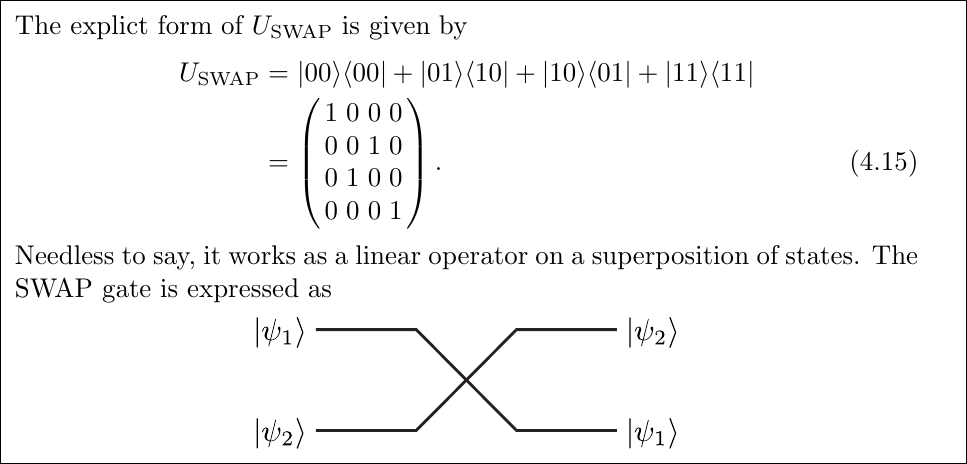

In [23]:
U_SWAP = P_00 + np.outer(ket_01, bra_10) + np.outer(ket_10, bra_01) + P_11
print(U_SWAP)

[[1 0 0 0]
 [0 0 1 0]
 [0 1 0 0]
 [0 0 0 1]]


### Fredkin gate
- Also called controlled SWAP gate


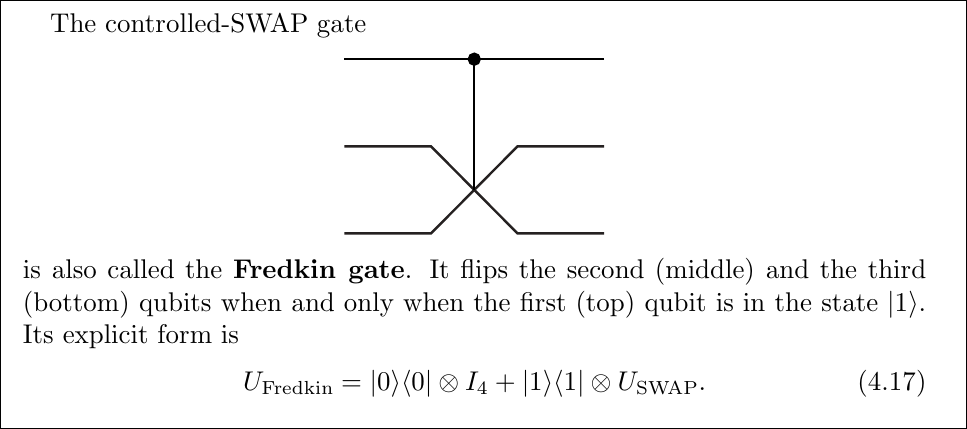

In [24]:
I_4 = np.eye(4)
U_Fredkin = np.kron(P0, I_4) + np.kron(P1, U_SWAP)
print(U_Fredkin)

[[1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1.]]


### Check for gate properties
- Mainly checking for Unitary and Hermitian

In [20]:
def check_gate_properties(gate_matrix, gate_name):
    # Check if the matrix is unitary (U†U = I)
    is_unitary = np.allclose(gate_matrix.conj().T @ gate_matrix, np.eye(gate_matrix.shape[0]))
    
    # Check if the matrix is Hermitian (U = U†) - true for CNOT & Toffoli
    is_hermitian = np.allclose(gate_matrix, gate_matrix.conj().T)
    
    print(f"\n--- {gate_name} ---")
    print(f"Unitary: {is_unitary}")
    print(f"Hermitian: {is_hermitian}")

In [25]:
check_gate_properties(X, "Pauli-X")
check_gate_properties(Z, "Pauli-Z")
check_gate_properties(H, "Hadamard")
check_gate_properties(U_CNOT, "CNOT")
check_gate_properties(U_CCNOT, "CCNOT (Toffoli)")
check_gate_properties(U_SWAP, "SWAP")
check_gate_properties(U_Fredkin, "Control-SWAP (Fredkin)")


--- Pauli-X ---
Unitary: True
Hermitian: True

--- Pauli-Z ---
Unitary: True
Hermitian: True

--- Hadamard ---
Unitary: True
Hermitian: True

--- CNOT ---
Unitary: True
Hermitian: True

--- CCNOT (Toffoli) ---
Unitary: True
Hermitian: True

--- SWAP ---
Unitary: True
Hermitian: True

--- Control-SWAP (Fredkin) ---
Unitary: True
Hermitian: True
